# 05 - Portfolio backtest: evaluation, sensitivities and reporting

**Owner: yae. Current progress: steps 1-15.**

Continue the fixed outputs of notebooks 01-04 and the original six official forecasts.
Steps 1-10 below read and hash-verify saved manifests/tables; they do not regenerate
historical outputs, refit diagnostic models or replay threshold candidates.
Steps 5-8 retain explicitly historical engineering previews. Step 10 documents the
complete validation-only selection of the public 15/7.5 bps threshold.

Step 11 freezes the complete protocol, reuses the selected validation ledger and
runs the six fixed-rule test strategies. A completed step-11 cache is verified and
loaded without replay. Validation remains tuning evidence; prior test forecast
metrics and exploratory GBDT provenance preclude an untouched-blind-holdout claim.

Functions remain in `scripts/` and outputs in `results/backtest/`. Original data,
notebooks 01-04, model predictions and previously registered outputs are unchanged.
Step 12 adds SPY fixed-share buy-and-hold and cash investment benchmarks using the
same phase dates. SPY entry shares reserve the 3 bps fee within capital 1; dividends
remain cash and earn subsequent-interval interest. Completed benchmark outputs are
verified without replay. Step 13 independently reconciles all selected strategy
and benchmark paths and checks deterministic behavior without complete portfolio
replays. Step 14 reuses all main paths, reports full metrics and figures, and evaluates the
seven frozen alternative cost assumptions. Completed scenario checkpoints are
verified without repeat replay. Step 15 packages these accepted outputs without additional experiments. Step 16 has not been run.


## 1. Environment and paths

Use the existing project environment. The panel step uses pandas, already listed in
`requirements.txt`. Like notebook 03, resolve the repository from either its root or
`notebooks/`. The script keeps the same `(date, ticker)` merge, `float_precision='round_trip'`
and UTC-to-New-York timestamp conventions as notebooks 02-04.


In [1]:
from pathlib import Path
import sys
import platform
import json
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data/processed/panel_spec.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/panel_spec.json').exists(), 'Run from repository root or notebooks/'
OUT = ROOT / 'results/backtest'
SCRIPT_DIR = str(ROOT / 'scripts')
if SCRIPT_DIR not in sys.path:
    sys.path.insert(0, SCRIPT_DIR)
from prepare_backtest_inputs import prepare_phase_evaluation
from backtest_investment_benchmarks import run_investment_benchmarks
from backtest_consistency_audit import run_consistency_audit
from backtest_reporting import run_reporting
from backtest_threshold_selection import sha256


def load_completed_manifest(relative_path):
    """Read historical results without changing their outputs or manifests."""
    path = OUT / relative_path
    record = json.loads(path.read_text(encoding='utf-8'))
    for item in record.get('outputs', []):
        assert sha256(ROOT / item['path']) == item['sha256'], item['path']
    return record


print('Python', platform.python_version(), '| pandas', pd.__version__)
print('Output:', OUT)


Python 3.11.5 | pandas 2.0.3
Output: D:\桌面文件\NUS_sem1\DSA5205\Project2\DSA5205_Project2-main\results\backtest


## 2. Step 1 - Receive all six forecast strategies

Inspect the saved intake checks for the seven-column interface, unique keys,
finite predictions and complete nine-sector coverage. This notebook reads and
hash-verifies completed outputs; the original preparation function remains in
`scripts/` for explicitly requested regeneration.


In [2]:
intake = load_completed_manifest('input_manifest.json')
display(pd.DataFrame(intake['strategies']))
print('Combined forecast rows:', f"{intake['combined_prediction_rows']:,}")


,model,scheme,prediction_rows,signal_dates,sectors_per_date,first_signal_date,last_signal_date
0,elastic_net,S0,19782,2198,9,2018-01-02,2026-09-30
1,elastic_net,S1,19782,2198,9,2018-01-02,2026-09-30
2,elastic_net,S2,19782,2198,9,2018-01-02,2026-09-30
3,gbdt,S0,19782,2198,9,2018-01-02,2026-09-30
4,gbdt,S1,19782,2198,9,2018-01-02,2026-09-30
5,gbdt,S2,19782,2198,9,2018-01-02,2026-09-30


Combined forecast rows: 118,692


## 3. Step 2 - Shared panel and monthly time interface

Connect forecasts to the panel using a many-to-one `(date, ticker)` join. Require exactly
the validation/test keys with `common_features_valid=True` for every model/scheme.
Reconstruct next-open and second-next-open mappings from the aligned SPY calendar;
localize 18:00 signals and 09:30 opens in `America/New_York` to handle daylight saving.

Each monthly fitting cutoff must be 18:00 on the SPY trading day before that month's
first signal. Compare monthly dates and coverage with notebook 02's existing audit.
Keep all forecast rows, including boundary and unscoreable rows; eligibility actions
belong to step 3. No positions or portfolio returns are computed here.


In [3]:
alignment = load_completed_manifest('panel_alignment_manifest.json')
summary = pd.read_csv(OUT / 'panel_alignment_summary.csv', low_memory=False)
display(summary)
print('Joined forecast rows:', f"{alignment['joined_prediction_rows']:,}")
print('Monthly model/scheme checks:', alignment['monthly_strategy_checks'])
print('Upstream month/sector records:', alignment['upstream_month_sector_checks'])


,model,scheme,split,prediction_rows,signal_dates,scoreable_rows,missing_entry_rows,missing_exit_rows,first_signal_date,last_signal_date,unscoreable_rows
0,elastic_net,S0,validation,11331,1259,11313,0,0,2018-01-02,2022-12-30,18
1,elastic_net,S1,validation,11331,1259,11313,0,0,2018-01-02,2022-12-30,18
2,elastic_net,S2,validation,11331,1259,11313,0,0,2018-01-02,2022-12-30,18
3,gbdt,S0,validation,11331,1259,11313,0,0,2018-01-02,2022-12-30,18
4,gbdt,S1,validation,11331,1259,11313,0,0,2018-01-02,2022-12-30,18
5,gbdt,S2,validation,11331,1259,11313,0,0,2018-01-02,2022-12-30,18
6,elastic_net,S0,test,8451,939,8433,9,18,2023-01-03,2026-09-30,18
7,elastic_net,S1,test,8451,939,8433,9,18,2023-01-03,2026-09-30,18
8,elastic_net,S2,test,8451,939,8433,9,18,2023-01-03,2026-09-30,18
9,gbdt,S0,test,8451,939,8433,9,18,2023-01-03,2026-09-30,18


Joined forecast rows: 118,692
Monthly model/scheme checks: 630
Upstream month/sector records: 945


## 4. Inspect timing examples

These dates show the first signal, the validation/test boundary, daylight-saving
weekends and the final available opens. `date` remains the signal date.
A missing future endpoint is retained as missing; no October 2026 price is introduced.
The displayed example uses XLB / Elastic Net / S0; all six strategies are checked.


In [4]:
examples = pd.read_csv(OUT / 'time_alignment_examples.csv',
                       parse_dates=['date', 'entry_date', 'exit_date'], low_memory=False)
for field in ['fit_cutoff', 'signal_at', 'entry_at', 'label_available_at']:
    examples[field] = pd.to_datetime(examples[field], utc=True).dt.tz_convert('America/New_York')
with pd.option_context('display.max_columns', None):
    display(examples)


,date,split,fit_cutoff,signal_at,entry_date,entry_at,exit_date,label_available_at,common_features_valid,label_valid,label_within_split,common_scoreable
0,2018-01-02,validation,2017-12-29 18:00:00-05:00,2018-01-02 18:00:00-05:00,2018-01-03,2018-01-03 09:30:00-05:00,2018-01-04,2018-01-04 09:30:00-05:00,True,True,True,True
1,2022-12-28,validation,2022-11-30 18:00:00-05:00,2022-12-28 18:00:00-05:00,2022-12-29,2022-12-29 09:30:00-05:00,2022-12-30,2022-12-30 09:30:00-05:00,True,True,True,True
2,2022-12-29,validation,2022-11-30 18:00:00-05:00,2022-12-29 18:00:00-05:00,2022-12-30,2022-12-30 09:30:00-05:00,2023-01-03,2023-01-03 09:30:00-05:00,True,True,False,False
3,2022-12-30,validation,2022-11-30 18:00:00-05:00,2022-12-30 18:00:00-05:00,2023-01-03,2023-01-03 09:30:00-05:00,2023-01-04,2023-01-04 09:30:00-05:00,True,True,False,False
4,2023-01-03,test,2022-12-30 18:00:00-05:00,2023-01-03 18:00:00-05:00,2023-01-04,2023-01-04 09:30:00-05:00,2023-01-05,2023-01-05 09:30:00-05:00,True,True,True,True
5,2025-10-31,test,2025-09-30 18:00:00-04:00,2025-10-31 18:00:00-04:00,2025-11-03,2025-11-03 09:30:00-05:00,2025-11-04,2025-11-04 09:30:00-05:00,True,True,True,True
6,2026-03-06,test,2026-02-27 18:00:00-05:00,2026-03-06 18:00:00-05:00,2026-03-09,2026-03-09 09:30:00-04:00,2026-03-10,2026-03-10 09:30:00-04:00,True,True,True,True
7,2026-09-28,test,2026-08-31 18:00:00-04:00,2026-09-28 18:00:00-04:00,2026-09-29,2026-09-29 09:30:00-04:00,2026-09-30,2026-09-30 09:30:00-04:00,True,True,True,True
8,2026-09-29,test,2026-08-31 18:00:00-04:00,2026-09-29 18:00:00-04:00,2026-09-30,2026-09-30 09:30:00-04:00,NaT,NaT,True,False,False,False
9,2026-09-30,test,2026-08-31 18:00:00-04:00,2026-09-30 18:00:00-04:00,NaT,NaT,NaT,NaT,True,False,False,False


## 5. Step 3 - Scoring eligibility and signal-time trading status

The trading policy receives only input validity, the seven forecast fields and the
signal/next-open calendar. It does not receive labels, `common_scoreable`, realized
returns, exit dates or mixed feature/label reason codes. Scoring uses a separate table.

Reindex every phase signal date onto all six strategies and nine sectors. Incomplete
signals request `CLOSE_ALL_TO_CASH` at the next open. Complete signals request
`EVALUATE_SIGNAL`; ranking and threshold decisions remain pending. The prespecified
final open requests `FINAL_LIQUIDATION`; later phase signals create no order.

An empty target pair set is only an instruction here. Actual shares, execution, fees
and the cash ledger are implemented later. Fault cases run on in-memory copies.


In [5]:
eligibility = load_completed_manifest('signal_policy_manifest.json')
eligibility_summary = pd.read_csv(OUT / 'eligibility_summary.csv', low_memory=False)
display(eligibility_summary)
print('Daily strategy states:', f"{eligibility['daily_strategy_rows']:,}")
print('Actions:', eligibility['action_counts'])
status_examples = pd.read_csv(OUT / 'signal_status_examples.csv', low_memory=False)
display(status_examples.loc[status_examples['model'].eq('gbdt') & status_examples['scheme'].eq('S1'),
    ['date', 'split', 'signal_complete', 'action', 'action_at', 'force_flat', 'reason']])


,model,scheme,split,signal_days,complete_signal_days,evaluate_signal_days,missing_signal_close_days,scheduled_liquidation_days,outside_phase_days,panel_scoreable_rows,score_eligible_rows
0,elastic_net,S0,test,939,939,937,0,1,1,8433,8433
1,elastic_net,S0,validation,1259,1259,1257,0,1,1,11313,11313
2,elastic_net,S1,test,939,939,937,0,1,1,8433,8433
3,elastic_net,S1,validation,1259,1259,1257,0,1,1,11313,11313
4,elastic_net,S2,test,939,939,937,0,1,1,8433,8433
5,elastic_net,S2,validation,1259,1259,1257,0,1,1,11313,11313
6,gbdt,S0,test,939,939,937,0,1,1,8433,8433
7,gbdt,S0,validation,1259,1259,1257,0,1,1,11313,11313
8,gbdt,S1,test,939,939,937,0,1,1,8433,8433
9,gbdt,S1,validation,1259,1259,1257,0,1,1,11313,11313


Daily strategy states: 13,188
Actions: {'EVALUATE_SIGNAL': 13164, 'FINAL_LIQUIDATION': 12, 'NO_ORDER_OUTSIDE_PHASE': 12}


,date,split,signal_complete,action,action_at,force_flat,reason
4,2020-03-24,validation,True,EVALUATE_SIGNAL,2020-03-25 09:30:00-04:00,False,OK
10,2022-12-28,validation,True,EVALUATE_SIGNAL,2022-12-29 09:30:00-05:00,False,OK
16,2022-12-29,validation,True,FINAL_LIQUIDATION,2022-12-30 09:30:00-05:00,True,scheduled_phase_end;OK
22,2022-12-30,validation,True,NO_ORDER_OUTSIDE_PHASE,NaN,False,outside_phase_order_schedule;OK
28,2026-09-28,test,True,EVALUATE_SIGNAL,2026-09-29 09:30:00-04:00,False,OK
34,2026-09-29,test,True,FINAL_LIQUIDATION,2026-09-30 09:30:00-04:00,True,scheduled_phase_end;OK
40,2026-09-30,test,True,NO_ORDER_OUTSIDE_PHASE,NaN,False,outside_phase_order_schedule;OK


## 6. Step 4 - Zero and monthly historical-mean prediction baselines

Reuse the `historical_mean` delivered in the Elastic Net full export after checking
agreement with GBDT and independently recomputing every monthly sector mean from the
same mature-label training rule. Training expands from 2008; both the signal and label
must be available by the monthly cutoff. Do not restrict training to scoreable rows.

Export two seven-column baselines with `scheme='COMMON'`: `zero` and `historical_mean`.
One common baseline serves S0/S1/S2. The zero forecast is for prediction evaluation;
it does not authorize an arbitrary portfolio from nine tied predictions. Its direction
accuracy is N/A. Historical-mean trading, if later included, must use the public rules.

The comparison table uses identical scoring keys for six model strategies and both
baselines. These are forecast errors and OOS R-squared, not portfolio returns.
SPY buy-and-hold and cash investment benchmarks remain step 12.


In [6]:
baselines = load_completed_manifest('baseline_manifest.json')
comparison = pd.read_csv(OUT / 'prediction_comparison_metrics.csv', low_memory=False)
display(comparison)
mean_audit = pd.read_csv(OUT / 'monthly_baseline_audit.csv', low_memory=False)
print('Baseline forecast rows:', f"{baselines['baseline_prediction_rows']:,}")
print('Monthly training records checked:', baselines['monthly_training_records'])
print('Maximum absolute mean differences:')
print(mean_audit[['elastic_net_abs_difference', 'gbdt_abs_difference']].max())


,model,scheme,split,n,MSE,RMSE,MAE,R2_OOS_mean,R2_OOS_zero,direction_accuracy
0,elastic_net,S0,test,8433,0.000092,0.009566,0.006932,-0.000473,-0.000273,0.508241
1,elastic_net,S0,validation,11313,0.000099,0.009963,0.006759,-0.000691,-0.001015,0.504375
2,elastic_net,S1,test,8433,0.000092,0.009566,0.006932,-0.000473,-0.000273,0.508241
3,elastic_net,S1,validation,11313,0.000099,0.009962,0.006759,-0.000605,-0.000930,0.504552
4,elastic_net,S2,test,8433,0.000092,0.009566,0.006932,-0.000473,-0.000273,0.508241
5,elastic_net,S2,validation,11313,0.000099,0.009962,0.006759,-0.000605,-0.000930,0.504552
6,gbdt,S0,test,8433,0.000091,0.009563,0.006931,0.000261,0.000461,0.503735
7,gbdt,S0,validation,11313,0.000099,0.009948,0.006752,0.002199,0.001875,0.511712
8,gbdt,S1,test,8433,0.000091,0.009562,0.006935,0.000429,0.000629,0.497569
9,gbdt,S1,validation,11313,0.000099,0.009941,0.006752,0.003587,0.003264,0.511977


Baseline forecast rows: 39,564
Monthly training records checked: 945
Maximum absolute mean differences:
elastic_net_abs_difference    0
gbdt_abs_difference           0
dtype: int64


## 7. Step 5 - Retention, exit, reversal and new entry

Use the existing Elastic Net/GBDT `y_hat` values and step-3 instructions. Step 3 is an
input/phase guard, not another prediction model. The group protocol already defines
the rules; no new manual trading directions are required.

For a normal complete signal: retain old pairs strictly beyond the half-threshold
exit bound, then fill at most four total slots using only the global top four absolute
predictions. Retained pairs may be outside today's top four. Ties use the fixed sector
order. A reversal requires full opposite entry eligibility and is returned as one final
target direction. Missing-signal/phase-end guards run first.

`decide_pairs` requires an explicit decimal entry threshold. The following integration
example uses 10 bps on only the first five validation signals; it is not a final threshold
selection or a performance experiment. Public threshold selection remains step 10.
Directions are logical targets, not share positions, executed trades or portfolio returns.


In [7]:
pair_rules = load_completed_manifest('pair_decision_manifest.json')
demo = pd.read_csv(OUT / 'pair_decision_demo_daily.csv', low_memory=False, keep_default_na=False)
display(demo.loc[demo['model'].eq('gbdt') & demo['scheme'].eq('S1'),
    ['date', 'model', 'scheme', 'previous_pair_directions', 'target_pair_directions',
     'previous_pairs', 'target_pairs', 'effective_action']])
print('Engineering example only:', pair_rules['example_only'])
print('Final threshold selected:', pair_rules['threshold_selection_performed'])
print('Example entry/exit bps:', pair_rules['example_entry_bps'], pair_rules['example_exit_bps'])
print('Daily/sector example rows:', pair_rules['daily_example_rows'], pair_rules['sector_example_rows'])


,date,model,scheme,previous_pair_directions,target_pair_directions,previous_pairs,target_pairs,effective_action
20,2018-01-02,gbdt,S1,,,0,0,EVALUATE_SIGNAL
21,2018-01-03,gbdt,S1,,,0,0,EVALUATE_SIGNAL
22,2018-01-04,gbdt,S1,,,0,0,EVALUATE_SIGNAL
23,2018-01-05,gbdt,S1,,,0,0,EVALUATE_SIGNAL
24,2018-01-08,gbdt,S1,,XLE:-1,0,1,EVALUATE_SIGNAL


Engineering example only: True
Final threshold selected: False
Example entry/exit bps: 10 5.0
Daily/sector example rows: 30 270


## 8. Step 6 - Target weights, SPY netting and net share plans

Each active pair allocates +/-12.5% of caller-supplied pre-trade NAV to the sector
and the opposite SPY leg. Combine SPY first, then compute target shares from observed
opens and trade only target minus current signed shares. Do not rescale fewer pairs,
round fractional shares or suppress small rebalancing differences.

The net-trade API takes actual old shares and settled NAV_pre as explicit inputs.
The next cash/NAV ledger step will supply them after dividend/interest/borrow settlement.
Missing required execution quotes are errors; adjusted prices and price fills are unused.

The real-data example below shows weights and shares per unit NAV at the next observed
open for the same five validation signals. It is not a historical share replay. Separate
worked examples use hypothetical, explicitly stated NAV/old shares to verify net trades.
No execution fees or portfolio returns are computed in this step.


In [8]:
execution = load_completed_manifest('execution_manifest.json')
weight_summary = pd.read_csv(OUT / 'execution_target_demo_daily.csv', low_memory=False)
display(weight_summary.loc[weight_summary['model'].eq('gbdt') & weight_summary['scheme'].eq('S1')])
worked = pd.read_csv(OUT / 'net_trade_worked_examples.csv', low_memory=False, float_precision='round_trip')
display(worked.loc[worked['trade_notional'].ne(0),
    ['example_case', 'ticker', 'nav_pre', 'current_shares', 'target_shares', 'delta_shares', 'trade_notional']])
print('Normalized asset targets:', execution['asset_target_examples'])
print('Actual NAV ledger implemented:', execution['actual_nav_ledger_implemented'])


,date,model,scheme,split,action_at,pair_count,gross_weight_before_spy_netting,target_gross_weight,target_net_weight,example_only,normalized_target_only,threshold_selected
20,2018-01-02,gbdt,S1,validation,2018-01-03 09:30:00-05:00,0,0.00,0.00,0,True,True,False
21,2018-01-03,gbdt,S1,validation,2018-01-04 09:30:00-05:00,0,0.00,0.00,0,True,True,False
22,2018-01-04,gbdt,S1,validation,2018-01-05 09:30:00-05:00,0,0.00,0.00,0,True,True,False
23,2018-01-05,gbdt,S1,validation,2018-01-08 09:30:00-05:00,0,0.00,0.00,0,True,True,False
24,2018-01-08,gbdt,S1,validation,2018-01-09 09:30:00-05:00,1,0.25,0.25,0,True,True,False


,example_case,ticker,nav_pre,current_shares,target_shares,delta_shares,trade_notional
0,initial_entry,XLB,100000,0.0,125.000000,125.000000,12500.00
9,initial_entry,SPY,100000,0.0,-62.500000,-62.500000,12500.00
20,retained_pair_rebalanced,XLB,101250,125.0,115.056818,-9.943182,1093.75
29,retained_pair_rebalanced,SPY,101250,-62.5,-63.281250,-0.781250,156.25
30,pair_reversal,XLB,100000,125.0,-125.000000,-250.000000,25000.00
39,pair_reversal,SPY,100000,-62.5,62.500000,125.000000,25000.00
40,sector_rotation_spy_unchanged,XLB,100000,125.0,0.000000,-125.000000,12500.00
41,sector_rotation_spy_unchanged,XLE,100000,0.0,250.000000,250.000000,12500.00
50,opposite_pairs_close_old_spy,XLB,100000,0.0,125.000000,125.000000,12500.00
51,opposite_pairs_close_old_spy,XLE,100000,0.0,-250.000000,-250.000000,12500.00


Normalized asset targets: 300
Actual NAV ledger implemented: False


## 9. Step 7 - Open-to-open cash, shares and NAV ledger

At each scheduled open, accrue old signed-share dividends, last-interval interest and
borrow expense before computing NAV_pre. Main interest uses max(previous cash minus
starting net short collateral, 0). Use exported interval risk-free returns directly;
borrow fees use actual natural days / 365. Short proceeds carry a matching negative
security value. New ex-date purchases receive no old-share dividend.

Pass settled NAV_pre and actual current shares to the step-6 planner, execute net
changes, then deduct execution fees once. Check both the settlement and trading NAV
identities. Initial and final fees are retained; the initial open is not a holding
interval, and the first actual interval includes the initial entry fee.

The API has explicit cost parameters. This engineering preview uses the documented
main values (3 bps execution, 1% annual borrow, no short-collateral rebate), with the
same first five validation signals and provisional 10 bps threshold. It starts from
unit capital and now carries actual simulated cash/shares through the preview. The
preview is truncated and is not a completed phase evaluation. Formal cost configuration
and sensitivity comparisons remain step 8.


In [9]:
ledger = load_completed_manifest('ledger_manifest.json')
book = pd.read_csv(OUT / 'ledger_demo_daily.csv', low_memory=False, float_precision='round_trip')
display(book.loc[book['model'].eq('gbdt') & book['scheme'].eq('S1'),
    ['open_date', 'cash_prev', 'dividend_cash', 'cash_interest', 'borrow_fee',
     'execution_fee', 'cash_post', 'nav_post', 'is_initial_open']])
worked_ledger = pd.read_csv(OUT / 'ledger_worked_examples.csv', low_memory=False, float_precision='round_trip')
display(worked_ledger.loc[worked_ledger['example_case'].isin([
    'initial_entry_fee', 'long_ex_dividend_exit', 'short_ex_dividend_exit',
    'own_cash_interest', 'weekend_borrow', 'final_liquidation_fee']),
    ['example_case', 'price_pnl', 'dividend_cash', 'cash_interest', 'borrow_fee',
     'execution_fee', 'nav_pre', 'nav_post']])
print('Ledger opens / asset rows:', ledger['daily_ledger_rows'], ledger['asset_ledger_rows'])
print('Matched cash intervals:', ledger['matched_rate_intervals'])
print('Max settlement/trading reconciliation errors:',
      ledger['max_pre_reconciliation_error'], ledger['max_post_reconciliation_error'])
print('Formal phase evaluation:', ledger['formal_phase_evaluation'])


,open_date,cash_prev,dividend_cash,cash_interest,borrow_fee,execution_fee,cash_post,nav_post,is_initial_open
20,2018-01-03,1.000000,0,0.000000,0,0.000000,1.000000,1.000000,True
21,2018-01-04,1.000000,0,0.000038,0,0.000000,1.000038,1.000038,False
22,2018-01-05,1.000038,0,0.000039,0,0.000000,1.000078,1.000078,False
23,2018-01-08,1.000078,0,0.000116,0,0.000000,1.000193,1.000193,False
24,2018-01-09,1.000193,0,0.000039,0,0.000075,1.000157,1.000157,False


,example_case,price_pnl,dividend_cash,cash_interest,borrow_fee,execution_fee,nav_pre,nav_post
1,initial_entry_fee,0,0,0.0,0.000000,7.5,100000.000000,99992.500000
3,long_ex_dividend_exit,-125,125,0.0,0.000000,0.0,100000.000000,100000.000000
4,short_ex_dividend_exit,125,-125,0.0,0.000000,0.0,100000.000000,100000.000000
6,own_cash_interest,0,0,87.5,0.000000,0.0,100087.500000,100087.500000
9,weekend_borrow,-1250,0,0.0,1.027397,0.0,98748.972603,98748.972603
12,final_liquidation_fee,0,0,0.0,0.000000,7.5,99992.500000,99985.000000


Ledger opens / asset rows: 30 300
Matched cash intervals: 24
Max settlement/trading reconciliation errors: 0.0 0.0
Formal phase evaluation: False


## 10. Step 8 - Shared cost policy and predefined comparisons

`scripts/backtest_costs.py` owns the shared protocol settings: 3 bps execution,
1% annual borrow and no collateral rebate. The exported JSON is a run snapshot.
Sensitivity comparisons change one factor at a time: execution 0/1/5 bps, borrow
0%/2%/3%, and full-cash rebate. Main plus seven changes gives eight scenarios.
The main case remains prespecified; no best-cost scenario or threshold is selected.

Export all settings before replay. Each case independently runs the same forecasts,
phase dates, capital and entry threshold through the ledger. Pair targets remain the
same; NAV-dependent share amounts may change. Fees are not simply subtracted from a
fixed gross-return curve.

The five-open market preview has no completed holding interval after its new shorts.
Borrow/rebate effects are therefore additionally tested on a synthetic four-open path
with three short-holding intervals, a weekend, dividends and final liquidation. Both
sets of tables are engineering verification, not completed validation/test evidence.


In [10]:
costs = load_completed_manifest('cost_manifest.json')
scenarios = pd.read_csv(OUT / 'cost_scenarios.csv', low_memory=False)
display(scenarios)
preview_costs = pd.read_csv(OUT / 'cost_preview_summary.csv', low_memory=False, float_precision='round_trip')
display(preview_costs.loc[preview_costs['model'].eq('gbdt') & preview_costs['scheme'].eq('S1'),
    ['scenario_id', 'sum_execution_fee', 'sum_borrow_fee', 'sum_cash_interest', 'borrow_exposed_intervals']])
synthetic_costs = pd.read_csv(OUT / 'cost_synthetic_summary.csv', low_memory=False, float_precision='round_trip')
display(synthetic_costs[['scenario_id', 'sum_execution_fee', 'sum_borrow_fee',
                       'sum_cash_interest', 'borrow_exposed_intervals']])
print('Shared main cost policy:', costs['main_cost_parameters'])
print('Scenarios / market comparison rows:', costs['scenario_count'], costs['market_preview_summary_rows'])
print('Final threshold selected:', costs['threshold_selection_performed'])


,scenario_id,variation,is_main,execution_bps,borrow_annual_rate,full_cash_rebate,borrow_annual_pct
0,main,main,True,3,0.01,False,1
1,execution_0,execution_bps,False,0,0.01,False,1
2,execution_1,execution_bps,False,1,0.01,False,1
3,execution_5,execution_bps,False,5,0.01,False,1
4,borrow_0,borrow_annual_rate,False,3,0.00,False,0
5,borrow_2,borrow_annual_rate,False,3,0.02,False,2
6,borrow_3,borrow_annual_rate,False,3,0.03,False,3
7,full_cash_rebate,full_cash_rebate,False,3,0.01,True,1


,scenario_id,sum_execution_fee,sum_borrow_fee,sum_cash_interest,borrow_exposed_intervals
4,main,0.000075,0,0.000232,0
10,execution_0,0.000000,0,0.000232,0
16,execution_1,0.000025,0,0.000232,0
22,execution_5,0.000125,0,0.000232,0
28,borrow_0,0.000075,0,0.000232,0
34,borrow_2,0.000075,0,0.000232,0
40,borrow_3,0.000075,0,0.000232,0
46,full_cash_rebate,0.000075,0,0.000232,0


,scenario_id,sum_execution_fee,sum_borrow_fee,sum_cash_interest,borrow_exposed_intervals
0,main,0.000152,0.000017,0.000438,3
1,execution_0,0.000000,0.000017,0.000438,3
2,execution_1,0.000051,0.000017,0.000438,3
3,execution_5,0.000253,0.000017,0.000438,3
4,borrow_0,0.000152,0.000000,0.000438,3
5,borrow_2,0.000152,0.000034,0.000438,3
6,borrow_3,0.000152,0.000051,0.000438,3
7,full_cash_rebate,0.000152,0.000017,0.000500,3


Shared main cost policy: {'execution_bps': 3.0, 'borrow_annual_rate': 0.01, 'full_cash_rebate': False}
Scenarios / market comparison rows: 8 48
Final threshold selected: False


## 11. Step 9 - Separate training-only forward signal-scale diagnostics

The original handoff contains only 2018+ forecasts. This workflow supplements it with
a diagnostic version: monthly expanding calibration during 2012 using history since 2008,
then monthly expanding forecasts during 2013-2017 with the 2012-selected parameters frozen.
Calibration labels must be available by 2012-12-31 18:00 New York. Nine sectors share
parameters within each model/specification; each sector has a separate fitted model.

The complete design and protocol threshold grid are registered before fitting. Original
notebooks, models, data and validation/test forecasts remain read-only. Outputs and
hash-checked monthly checkpoints live in `results/backtest/training_oof/`. Re-execution
verifies a completed cache rather than refitting. The first run can take several minutes.

The local sklearn 1.3 runtime has no `max_features` keyword; the requested GBDT value 1.0
is mapped to its all-feature behavior. Exact software versions are recorded; cross-version
bitwise equivalence to the original model fits is not claimed. Feature definitions and grids
already existed, so this is a retrospective diagnostic, not an untouched historical holdout.

Inspect absolute forecast quantiles and strict threshold exceedance, never portfolio
returns here. Retain valid individual-sector rows; rank top four only on complete-nine-sector
dates. Invalid XLF rows are not filled. The fixed 5/10/15/20/30 bps grid is not expanded
or selected from these diagnostics.


In [11]:
oof = load_completed_manifest('training_oof_manifest.json')
OOF_OUT = OUT / 'training_oof'
display(pd.read_csv(OOF_OUT / 'threshold_candidates.csv'))
for family in ['elastic_net', 'gbdt']:
    print('Training-only diagnostic parameters:', family)
    display(pd.read_csv(OOF_OUT / f'{family}_selected_diagnostic.csv'))
quantiles = pd.read_csv(OOF_OUT / 'signal_quantiles.csv')
display(quantiles.loc[quantiles.scope.eq('all_valid_sector_rows')])
exceedance = pd.read_csv(OOF_OUT / 'threshold_exceedance.csv')
display(exceedance.loc[exceedance.scope.eq('all_valid_sector_rows')])
print('OOF forecasts:', oof['prediction_rows'])
print('Calibration / OOF fits:', oof['calibration_fit_count'], '/', oof['oof_fit_count'])
print('Complete-nine-sector dates per strategy:', oof['complete_nine_sector_days_per_strategy'])
print('Public threshold selected:', oof['threshold_selection_performed'])


,entry_bps,exit_bps,selected
0,5,2.5,False
1,10,5.0,False
2,15,7.5,False
3,20,10.0,False
4,30,15.0,False


Training-only diagnostic parameters: elastic_net


,scheme,alpha,l1_ratio,n,sse,calibration_mse
0,S0,0.001,0.8,2232,0.060349,0.000027
1,S1,0.001,0.8,2232,0.060125,0.000027
2,S2,0.001,0.8,2232,0.060210,0.000027


Training-only diagnostic parameters: gbdt


,scheme,max_leaf_nodes,min_samples_leaf,l2_regularization,max_iter,n,sse,calibration_mse,stopping_round
0,S0,5,50,0,1,2232,0.059762,0.000027,11
1,S1,5,20,0,1,2232,0.059762,0.000027,11
2,S2,5,20,0,1,2232,0.059758,0.000027,11


,model,scheme,scope,rows,dates,mean_abs_bps,max_abs_bps,zero_fraction,p25_abs_bps,p50_abs_bps,p75_abs_bps,p90_abs_bps,p95_abs_bps,p99_abs_bps
0,elastic_net,S0,all_valid_sector_rows,10599,1199,2.024754,43.637715,0,0.497259,1.174474,2.383731,4.746121,7.195160,14.381731
6,elastic_net,S1,all_valid_sector_rows,10599,1199,2.082894,45.774836,0,0.499009,1.187039,2.412334,4.918099,7.469598,14.912760
12,elastic_net,S2,all_valid_sector_rows,10599,1199,2.086002,44.002787,0,0.499009,1.184602,2.413860,4.896044,7.469598,14.774904
18,gbdt,S0,all_valid_sector_rows,10599,1199,1.072861,5.110162,0,0.384709,0.764941,1.369383,2.581142,3.047715,3.754553
24,gbdt,S1,all_valid_sector_rows,10599,1199,1.083025,8.030881,0,0.426895,0.783644,1.360129,2.563770,3.016154,3.745052
30,gbdt,S2,all_valid_sector_rows,10599,1199,1.082991,8.030881,0,0.427417,0.783644,1.360129,2.564751,3.016154,3.745052


,model,scheme,scope,entry_bps,rows,exceeding_rows,fraction
0,elastic_net,S0,all_valid_sector_rows,5,10599,971,0.091612
1,elastic_net,S0,all_valid_sector_rows,10,10599,269,0.025380
2,elastic_net,S0,all_valid_sector_rows,15,10599,91,0.008586
3,elastic_net,S0,all_valid_sector_rows,20,10599,32,0.003019
4,elastic_net,S0,all_valid_sector_rows,30,10599,4,0.000377
30,elastic_net,S1,all_valid_sector_rows,5,10599,1031,0.097273
31,elastic_net,S1,all_valid_sector_rows,10,10599,306,0.028871
32,elastic_net,S1,all_valid_sector_rows,15,10599,103,0.009718
33,elastic_net,S1,all_valid_sector_rows,20,10599,27,0.002547
34,elastic_net,S1,all_valid_sector_rows,30,10599,6,0.000566


OOF forecasts: 63594
Calibration / OOF fits: 12636 / 3078
Complete-nine-sector dates per strategy: 1007
Public threshold selected: False


## 12. Step 10 - One public threshold selected on validation only

Use the original official 2018-2022 forecasts, not the separate training diagnostic.
Replay entry 5/10/15/20/30 bps (exit = half entry), with main execution/borrow/interest
settings. Each model/specification/candidate starts independently from cash 1 at
2018-01-03 open and finishes flat at 2022-12-30 open. All 1,257 holding intervals
count, including cash days; initial and final fees are included.

The objective is the equal-weight average of six mean daily net portfolio returns
minus same-interval cash returns. Exact ties use the higher threshold, with no
rounding before ranking. Report Sharpe, two-sided turnover and holding fraction
for every candidate/strategy. N/A Sharpe is retained for zero excess variance.
Holding fraction uses the position at the START of each interval; turnover includes
all actual net asset transactions, with no half factor.

The policy and runtime/source/engine hashes are recorded before replay. Five
candidate checkpoints preserve daily, share and trade ledgers. Completed results
are verified and loaded without replay. `selected_threshold.json` owns the public
selection; older unselected engineering/diagnostic snapshots remain historical.
No test strategy or alternative cost scenario is evaluated in this step.


In [12]:
thresholds = load_completed_manifest('threshold_selection/run_manifest.json')
THRESHOLD_OUT = OUT / 'threshold_selection'
candidate_scores = pd.read_csv(THRESHOLD_OUT / 'validation_candidate_scores.csv')
strategy_scores = pd.read_csv(THRESHOLD_OUT / 'validation_strategy_summary.csv')
display(candidate_scores.sort_values('entry_bps'))
display(strategy_scores[['entry_bps', 'model', 'scheme', 'mean_daily_cash_excess_bps',
    'annualized_cash_excess_sharpe', 'annualized_two_sided_turnover',
    'holding_interval_fraction', 'asset_trade_records', 'ending_nav']])
print('Selected public entry / exit (bps):', thresholds['selected_public_entry_bps'],
      '/', thresholds['selected_public_exit_bps'])
print('Official validation holding intervals per strategy:', thresholds['holding_intervals_per_strategy'])
print('Test strategy evaluated:', thresholds['test_strategy_evaluated'])


,entry_bps,strategy_count,holding_intervals_per_strategy,objective_mean_daily_cash_excess_return,mean_holding_interval_fraction,mean_annualized_two_sided_turnover,total_asset_trade_records,objective_mean_daily_cash_excess_bps,selection_rank,selected
3,5,6,1257,0.000023,0.579952,38.759228,13613,0.227764,4,False
1,10,6,1257,0.000025,0.295810,22.083821,7358,0.247302,2,False
0,15,6,1257,0.000041,0.136834,11.263420,3630,0.405908,1,True
2,20,6,1257,0.000024,0.083532,6.762668,2211,0.241988,3,False
4,30,6,1257,0.000014,0.040308,2.947912,1020,0.136638,5,False


,entry_bps,model,scheme,mean_daily_cash_excess_bps,annualized_cash_excess_sharpe,annualized_two_sided_turnover,holding_interval_fraction,asset_trade_records,ending_nav
0,5,elastic_net,S0,-0.423863,-0.680716,35.659034,0.583134,1970,1.011400
1,5,elastic_net,S1,-0.541894,-0.893118,36.456047,0.577566,1959,0.996535
2,5,elastic_net,S2,-0.541894,-0.893118,36.456047,0.577566,1959,0.996535
3,5,gbdt,S0,0.792460,0.557229,39.984789,0.580748,2570,1.175426
4,5,gbdt,S1,0.977980,0.631723,42.181036,0.587112,2612,1.202453
5,5,gbdt,S2,1.103796,0.723269,41.818413,0.573588,2543,1.221754
6,10,elastic_net,S0,-0.415707,-0.868198,18.065510,0.289578,1044,1.012690
7,10,elastic_net,S1,-0.336726,-0.722475,18.657342,0.285601,1032,1.022814
8,10,elastic_net,S2,-0.336726,-0.722475,18.657342,0.285601,1032,1.022814
9,10,gbdt,S0,0.771030,0.737675,26.359356,0.292761,1394,1.173996


Selected public entry / exit (bps): 15 / 7.5
Official validation holding intervals per strategy: 1257
Test strategy evaluated: False


## 13. Step 11 - Frozen protocol and separate phase evaluation

Freeze the complete input/model, signal, pair, execution, accounting, cost and
statistical rules before the first step-11 test portfolio replay. Use the original
official forecasts and the selected public 15/7.5 bps threshold for all six strategies.
Validation runs from 2018-01-03 to 2022-12-30 open; test runs from 2023-01-04 to
2026-09-30 open. Every strategy/phase starts from cash 1 with no shares and ends
flat with liquidation fees. No positions or capital carry across the phases.

Validation is read from the complete step-10 entry-15 ledger, without replay or
changing its role as tuning evidence. Test is replayed once through the unchanged
signed-share ledger under 3 bps execution, 1% annual borrow and no short-collateral
rebate. Completed phase outputs are hash-verified and loaded without replay.

All 12 model/scheme/phase rows are retained. Test forecast metrics were previously
viewed and the GBDT configuration discloses exploratory provenance; this is a
fixed-rule test-period evaluation, not an untouched blind holdout. No fitting,
threshold reselection, investment benchmark run or sensitivity replay occurs here.
The basic summary is not the complete reporting/figure work of step 14.


In [13]:
phases = prepare_phase_evaluation(ROOT)
PHASE_OUT = OUT / 'phase_evaluation'
phase_summary = pd.read_csv(PHASE_OUT / 'phase_summary.csv', low_memory=False, float_precision='round_trip')
display(phase_summary[['split', 'model', 'scheme', 'annualized_net_return',
    'annualized_cash_excess_sharpe', 'holding_interval_fraction',
    'annualized_two_sided_turnover', 'ending_nav', 'ledger_replayed_in_step11']])
print('Protocol frozen at (UTC):', phases['protocol_frozen_utc'])
print('Public entry / exit (bps):', phases['selected_public_entry_bps'], '/', phases['selected_public_exit_bps'])
print('Validation replayed:', phases['validation_replayed'])
print('Test strategy evaluated:', phases['test_strategy_evaluated'])
for phase, detail in phases['phases'].items():
    print(phase, ':', detail['opening_records_per_strategy'], 'opens /',
          detail['holding_intervals_per_strategy'], 'holding intervals per strategy')
print('Prior test forecast metrics were viewed; no untouched blind holdout is claimed.')


Step 11: verified frozen protocol and completed phase cache; no replay


,split,model,scheme,annualized_net_return,annualized_cash_excess_sharpe,holding_interval_fraction,annualized_two_sided_turnover,ending_nav,ledger_replayed_in_step11
0,validation,elastic_net,S0,0.014174,0.127072,0.104216,7.478697,1.072726,False
1,validation,elastic_net,S1,0.012412,-0.083419,0.101830,7.771570,1.063463,False
2,validation,elastic_net,S2,0.012412,-0.083419,0.101830,7.771570,1.063463,False
3,validation,gbdt,S0,0.035111,0.937020,0.180589,14.059349,1.187837,False
4,validation,gbdt,S1,0.035339,0.844250,0.171042,15.628921,1.189139,False
5,validation,gbdt,S2,0.031284,0.700386,0.161496,14.870414,1.166089,False
6,test,elastic_net,S0,0.046880,-0.398683,0.011740,0.956718,1.185718,True
7,test,elastic_net,S1,0.046880,-0.398683,0.011740,0.956718,1.185718,True
8,test,elastic_net,S2,0.046880,-0.398683,0.011740,0.956718,1.185718,True
9,test,gbdt,S0,0.044197,-0.231089,0.137673,8.013172,1.174460,True


Protocol frozen at (UTC): 2026-10-31T09:45:00.086023+00:00
Public entry / exit (bps): 15 / 7.5
Validation replayed: False
Test strategy evaluated: True
validation : 1258 opens / 1257 holding intervals per strategy
test : 938 opens / 937 holding intervals per strategy
Prior test forecast metrics were viewed; no untouched blind holdout is claimed.


## 14. Step 12 - SPY buy-and-hold and cash investment benchmarks

The step-11 frozen protocol and all acceptance checks are prerequisites. Both
benchmarks use exactly the same phase opens, capital 1 and exported available RF
intervals as the saved strategies. No strategy is replayed and no threshold is chosen.

SPY buys fixed fractional shares at the first observed open. Initial shares are
1 / ((1 + 3/10000) * first open), reserving the entry fee within capital 1. Shares
stay fixed until final liquidation; dividends go to cash, earn interest from the
following interval and are not reinvested in SPY. The final sale pays the same 3 bps
fee after old-share dividend and cash-interest settlement. The initial entry fee
is retained in the first actual return interval; no zero-length return is inserted.

Cash compounds the same exported interval RF returns without security trades or
artificial trading fees. Both benchmarks restart separately at each phase. Raw
observed opens/dividends are used, with no adjusted-price or dividend double count.

The new standalone script preserves the frozen step-11 wrapper and all original
engine hashes. Completed benchmark caches are verified and loaded without replay.
SPY has full market exposure whereas the paired strategies have different exposure;
this comparison is between investable alternatives, not risk-matched portfolios.


In [14]:
investment_benchmarks = run_investment_benchmarks(ROOT)
INVESTMENT_OUT = OUT / 'investment_benchmarks'
investment_summary = pd.read_csv(INVESTMENT_OUT / 'benchmark_summary.csv', low_memory=False, float_precision='round_trip')
display(investment_summary[['split', 'benchmark', 'opening_records', 'holding_intervals',
    'annualized_net_return', 'annualized_cash_excess_sharpe', 'ending_nav',
    'total_execution_fee', 'total_dividend_cash', 'total_cash_interest']])
investment_comparison = pd.read_csv(INVESTMENT_OUT / 'strategy_benchmark_comparison.csv', low_memory=False, float_precision='round_trip')
display(investment_comparison[['split', 'model', 'scheme', 'annualized_net_return',
    'spy_buy_hold_benchmark_annualized_net_return', 'cash_benchmark_annualized_net_return',
    'ending_relative_to_spy_buy_hold_benchmark', 'ending_relative_to_cash_benchmark']])
print('Benchmark phase ledgers:', investment_benchmarks['phase_benchmark_count'])
print('Daily / interval / actual security-trade rows:', investment_benchmarks['daily_ledger_rows'],
      investment_benchmarks['return_rows'], investment_benchmarks['security_trade_rows'])
print('Original strategies replayed:', investment_benchmarks['original_strategy_replay'])


Step 12: verified completed investment benchmark cache; no replay


,split,benchmark,opening_records,holding_intervals,annualized_net_return,annualized_cash_excess_sharpe,ending_nav,total_execution_fee,total_dividend_cash,total_cash_interest
0,test,cash,938,937,0.048079,NaN,1.190775,0.000000,0.000000,0.190775
1,test,spy_buy_hold,938,937,0.216723,1.076355,2.073790,0.000900,0.069320,0.005435
2,validation,cash,1258,1257,0.013162,NaN,1.067400,0.000000,0.000000,0.067400
3,validation,spy_buy_hold,1258,1257,0.087998,0.465440,1.523018,0.000724,0.105731,0.002906


,split,model,scheme,annualized_net_return,spy_buy_hold_benchmark_annualized_net_return,cash_benchmark_annualized_net_return,ending_relative_to_spy_buy_hold_benchmark,ending_relative_to_cash_benchmark
0,validation,elastic_net,S0,0.014174,0.087998,0.013162,-0.295658,0.004990
1,validation,elastic_net,S1,0.012412,0.087998,0.013162,-0.301740,-0.003689
2,validation,elastic_net,S2,0.012412,0.087998,0.013162,-0.301740,-0.003689
3,validation,gbdt,S0,0.035111,0.087998,0.013162,-0.220076,0.112833
4,validation,gbdt,S1,0.035339,0.087998,0.013162,-0.219222,0.114052
5,validation,gbdt,S2,0.031284,0.087998,0.013162,-0.234356,0.092458
6,test,elastic_net,S0,0.046880,0.216723,0.048079,-0.428236,-0.004247
7,test,elastic_net,S1,0.046880,0.216723,0.048079,-0.428236,-0.004247
8,test,elastic_net,S2,0.046880,0.216723,0.048079,-0.428236,-0.004247
9,test,gbdt,S0,0.044197,0.216723,0.048079,-0.433665,-0.013701


Benchmark phase ledgers: 4
Daily / interval / actual security-trade rows: 4392 4388 4
Original strategies replayed: False


## 15. Step 13 - Independent accounting and deterministic consistency audit

Use the completed step-11/12 results as read-only evidence: twelve formal
15-bps model/scheme/phase paths and four investment-benchmark paths. Independent
arithmetic reconstructs asset and portfolio cash flows from original observed
opens/dividends, available RF intervals and saved shares. Stored residual columns
alone are not treated as proof. Both return products and PnL sums must reconstruct
NAV, including initial/final fees, and exported summaries must match the ledger.

Rebuild trading eligibility using only as-of fields; reversing row order and
poisoning future scoring/label fields must not change the result. An independent
retain/exit/top-four reference must match every saved target. All pair decisions
must remain exact when dictionary order changes. Selected single-open planner and
ledger calls test initial/final, retained rebalancing, reversal, netted SPY,
dividend and borrow cases where present. Identical official forecast paths must
produce identical saved ledgers. Tiny three-open fixtures check benchmark order.

Independent numeric reconstructions use registered absolute/relative tolerances;
input-order determinism requires exact equality in the recorded environment.
No full portfolio is replayed, model refitted, threshold reselected or sensitivity
run. Earlier candidate ledgers are protected by hashes; detailed numeric coverage
is the selected formal paths. Completed audit evidence is verified without rerun.


In [15]:
consistency = run_consistency_audit(ROOT)
AUDIT_OUT = OUT / 'consistency_audit'
audit_table = pd.read_csv(AUDIT_OUT / 'audit_checks.csv', low_memory=False)
display(audit_table.groupby('category', as_index=False).agg(
    checks=('passed', 'size'), passed=('passed', 'sum'), max_abs_error=('max_abs_error', 'max')))
display(pd.read_csv(AUDIT_OUT / 'strategy_reconciliation.csv'))
display(pd.read_csv(AUDIT_OUT / 'benchmark_reconciliation.csv'))
print('Audit status:', consistency['status'])
print('Paths: strategies', consistency['strategy_paths'], '/ benchmarks', consistency['benchmark_paths'])
print('Isolated single-open cases:', consistency['isolated_single_open_cases'])
print('Identical-prediction path pairs:', consistency['identical_prediction_path_pairs'])
print('Protected files:', consistency['protected_file_count'])
print('Complete strategy / benchmark replay:', consistency['full_strategy_replay'], '/', consistency['full_benchmark_replay'])


Step 13: verified completed independent audit cache; no repeat audit or portfolio replay


,category,checks,passed,max_abs_error
0,benchmark,96,96,4.440892e-15
1,comparison,10,10,0.000000e+00
2,determinism,358,358,0.000000e+00
3,pair_rules,48,48,NaN
4,provenance,1,1,NaN
5,signal_inputs,6,6,NaN
6,source_data,2,2,NaN
7,strategy,528,528,5.995204e-15


,phase,model,scheme,opens,intervals,asset_rows,trade_rows,saved_ending_nav,reconstructed_nav_product,reconstructed_nav_pnl,cash_carry_max_error,target_shares_max_error,independent_nav_max_error,pnl_ending_error
0,validation,elastic_net,S0,1258,1257,12580,392,1.072726,1.072726,1.072726,0,0.000000e+00,0.000000e+00,1.554312e-15
1,validation,elastic_net,S1,1258,1257,12580,392,1.063463,1.063463,1.063463,0,0.000000e+00,0.000000e+00,2.886580e-15
2,validation,elastic_net,S2,1258,1257,12580,392,1.063463,1.063463,1.063463,0,0.000000e+00,0.000000e+00,2.886580e-15
3,validation,gbdt,S0,1258,1257,12580,823,1.187837,1.187837,1.187837,0,0.000000e+00,2.220446e-16,2.220446e-16
4,validation,gbdt,S1,1258,1257,12580,840,1.189139,1.189139,1.189139,0,1.734723e-18,2.220446e-16,5.995204e-15
5,validation,gbdt,S2,1258,1257,12580,791,1.166089,1.166089,1.166089,0,8.673617e-19,2.220446e-16,1.998401e-15
6,test,elastic_net,S0,938,937,9380,34,1.185718,1.185718,1.185718,0,0.000000e+00,0.000000e+00,1.110223e-15
7,test,elastic_net,S1,938,937,9380,34,1.185718,1.185718,1.185718,0,0.000000e+00,0.000000e+00,1.110223e-15
8,test,elastic_net,S2,938,937,9380,34,1.185718,1.185718,1.185718,0,0.000000e+00,0.000000e+00,1.110223e-15
9,test,gbdt,S0,938,937,9380,378,1.174460,1.174460,1.174460,0,8.673617e-19,0.000000e+00,1.554312e-15


,phase,benchmark,opens,intervals,saved_ending_nav,independent_terminal_nav,independent_pnl_nav,max_nav_error,terminal_error
0,test,cash,938,937,1.190775,1.190775,1.190775,0,4.440892e-15
1,test,spy_buy_hold,938,937,2.073790,2.073790,2.073790,0,4.440892e-16
2,validation,cash,1258,1257,1.067400,1.067400,1.067400,0,3.996803e-15
3,validation,spy_buy_hold,1258,1257,1.523018,1.523018,1.523018,0,0.000000e+00


Audit status: passed
Paths: strategies 12 / benchmarks 4
Isolated single-open cases: 70
Identical-prediction path pairs: 3
Protected files: 528
Complete strategy / benchmark replay: False / False


## 16. Step 14 - Full metrics, figures and frozen cost sensitivities

Prerequisite: the complete step-13 independent consistency audit has passed.
Reuse all twelve accepted main-cost strategy paths and four investment benchmarks.
Report net total/CAGR, sample annualized net volatility, cash-excess Sharpe, signed
maximum drawdown, two-sided turnover, holding fraction and cash/fee decomposition.
Drawdown includes capital 1 before the initial entry fee and every post-open NAV.

The frozen cost policy has main plus seven alternatives: execution 0/1/5 bps,
annual borrow 0%/2%/3%, and full-cash rebate. Alternatives independently replay
NAV-dependent shares and financing under the same 15/7.5 bps threshold. Main books
are reused. Fourteen new phase/scenario batches evaluate 84 alternative strategy
paths; all 96 main/alternative rows are retained. No cost setting is selected.
The engineering preview wrapper is not used because its labels describe examples;
the unchanged full ledger and shared scenario definitions are reused directly.

Main figures compare all six strategies with cash and SPY. Annual returns group
actual intervals by ending-open year; phase boundaries apply, and 2026 only runs
to September 30, without annualizing that calendar-year result. Validation remains
tuning evidence, and prior test prediction exploration remains disclosed.

Complete checkpoints and reporting caches are hash-verified without replay. No
new model fitting or threshold search occurs; steps 15-16 remain separate.


Step 14: verified completed numeric reporting cache; no cost replay
Step 14: verified complete tables, figures and report cache; no replay or rendering


,split,series_id,annualized_net_return,annualized_net_volatility,annualized_cash_excess_sharpe,max_drawdown,annualized_two_sided_turnover,holding_interval_fraction
0,validation,elastic_net_S0,0.014174,0.008122,0.127072,-0.015674,7.478697,0.104216
1,validation,elastic_net_S1,0.012412,0.008475,-0.083419,-0.019405,7.771570,0.101830
2,validation,elastic_net_S2,0.012412,0.008475,-0.083419,-0.019405,7.771570,0.101830
3,validation,gbdt_S0,0.035111,0.023173,0.937020,-0.023271,14.059349,0.180589
4,validation,gbdt_S1,0.035339,0.026049,0.844250,-0.036095,15.628921,0.171042
5,validation,gbdt_S2,0.031284,0.025791,0.700386,-0.036095,14.870414,0.161496
6,test,elastic_net_S0,0.046880,0.003369,-0.398683,-0.005772,0.956718,0.011740
7,test,elastic_net_S1,0.046880,0.003369,-0.398683,-0.005772,0.956718,0.011740
8,test,elastic_net_S2,0.046880,0.003369,-0.398683,-0.005772,0.956718,0.011740
9,test,gbdt_S0,0.044197,0.015584,-0.231089,-0.022748,8.013172,0.137673


,split,model,scheme,scenarios,min_annualized_net_return,max_annualized_net_return,min_cash_excess_sharpe,max_cash_excess_sharpe
0,test,elastic_net,S0,8,0.046680,0.047180,-0.466258,-0.296961
1,test,elastic_net,S1,8,0.046680,0.047180,-0.466258,-0.296961
2,test,elastic_net,S2,8,0.046680,0.047180,-0.466258,-0.296961
3,test,gbdt,S0,8,0.042525,0.046711,-0.334414,-0.076234
4,test,gbdt,S1,8,0.053423,0.058218,0.392449,0.731705
5,test,gbdt,S2,8,0.052582,0.057122,0.333483,0.657891
6,validation,elastic_net,S0,8,0.012657,0.016452,-0.057746,0.400360
7,validation,elastic_net,S1,8,0.010839,0.014775,-0.268210,0.191018
8,validation,elastic_net,S2,8,0.010839,0.014775,-0.268210,0.191018
9,validation,gbdt,S0,8,0.032206,0.039484,0.817209,1.115202


Reused main paths: 16
Sensitivity rows / new paths: 96 / 84
Original main strategies replayed: False
Chinese report: D:\桌面文件\NUS_sem1\DSA5205\Project2\DSA5205_Project2-main\results\backtest\reporting\report_中文.md


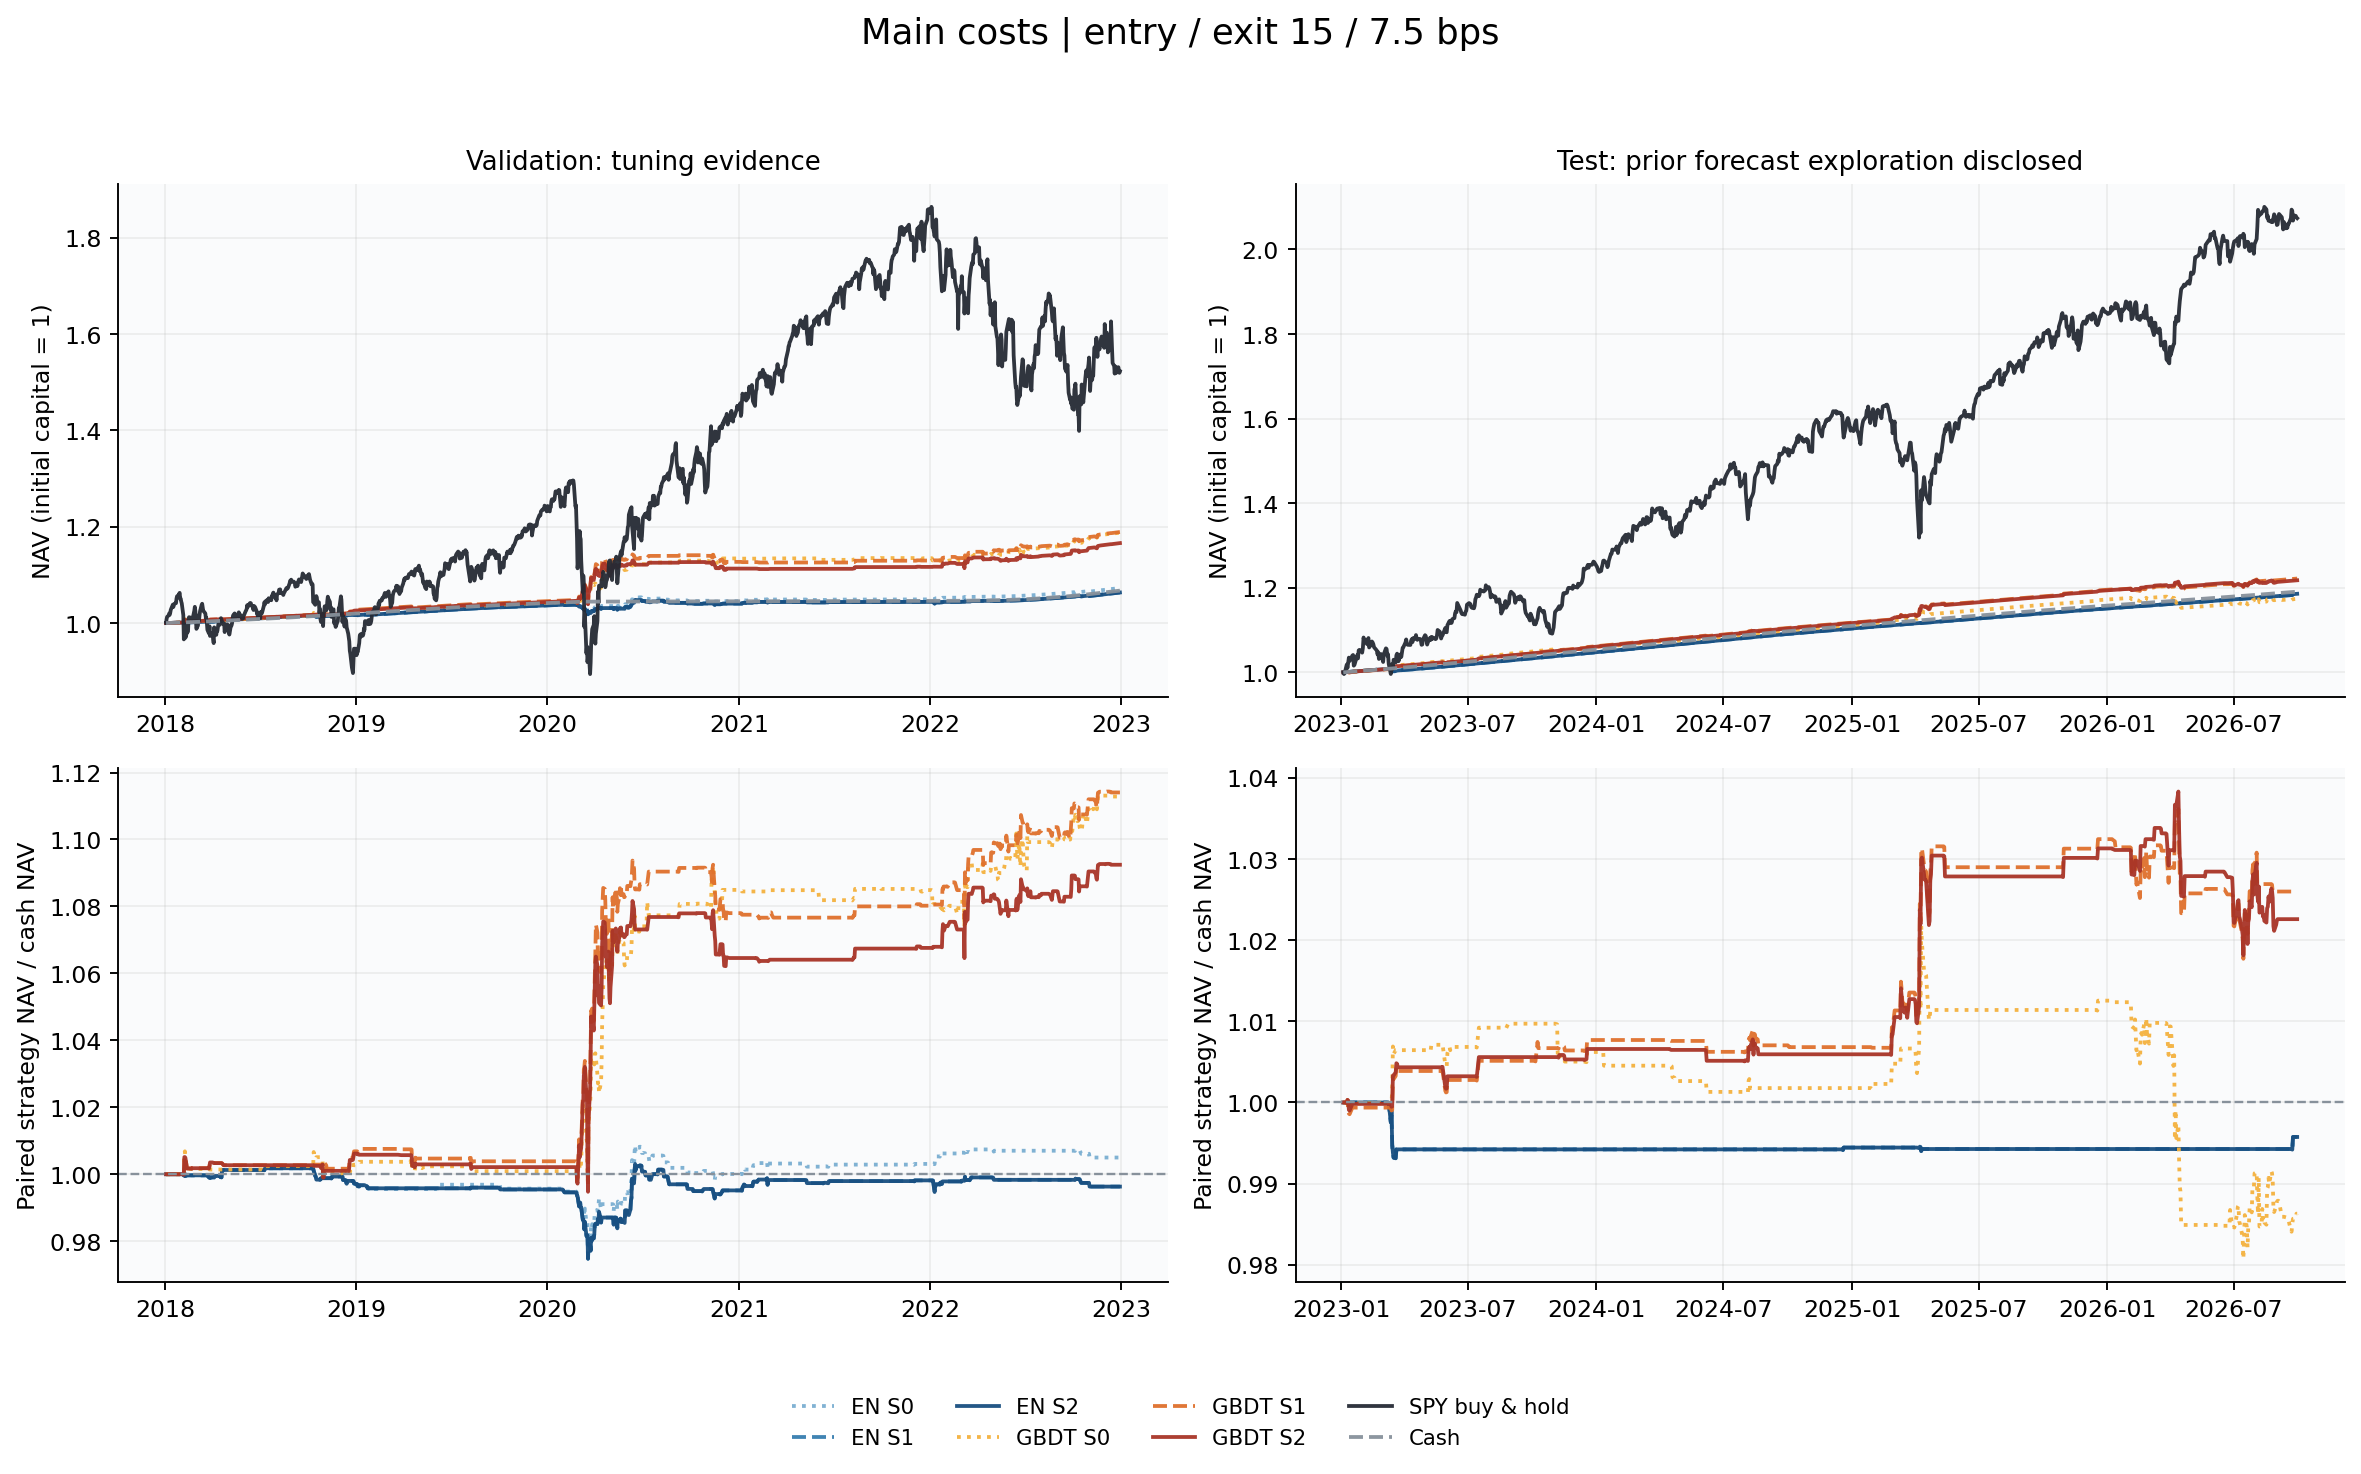

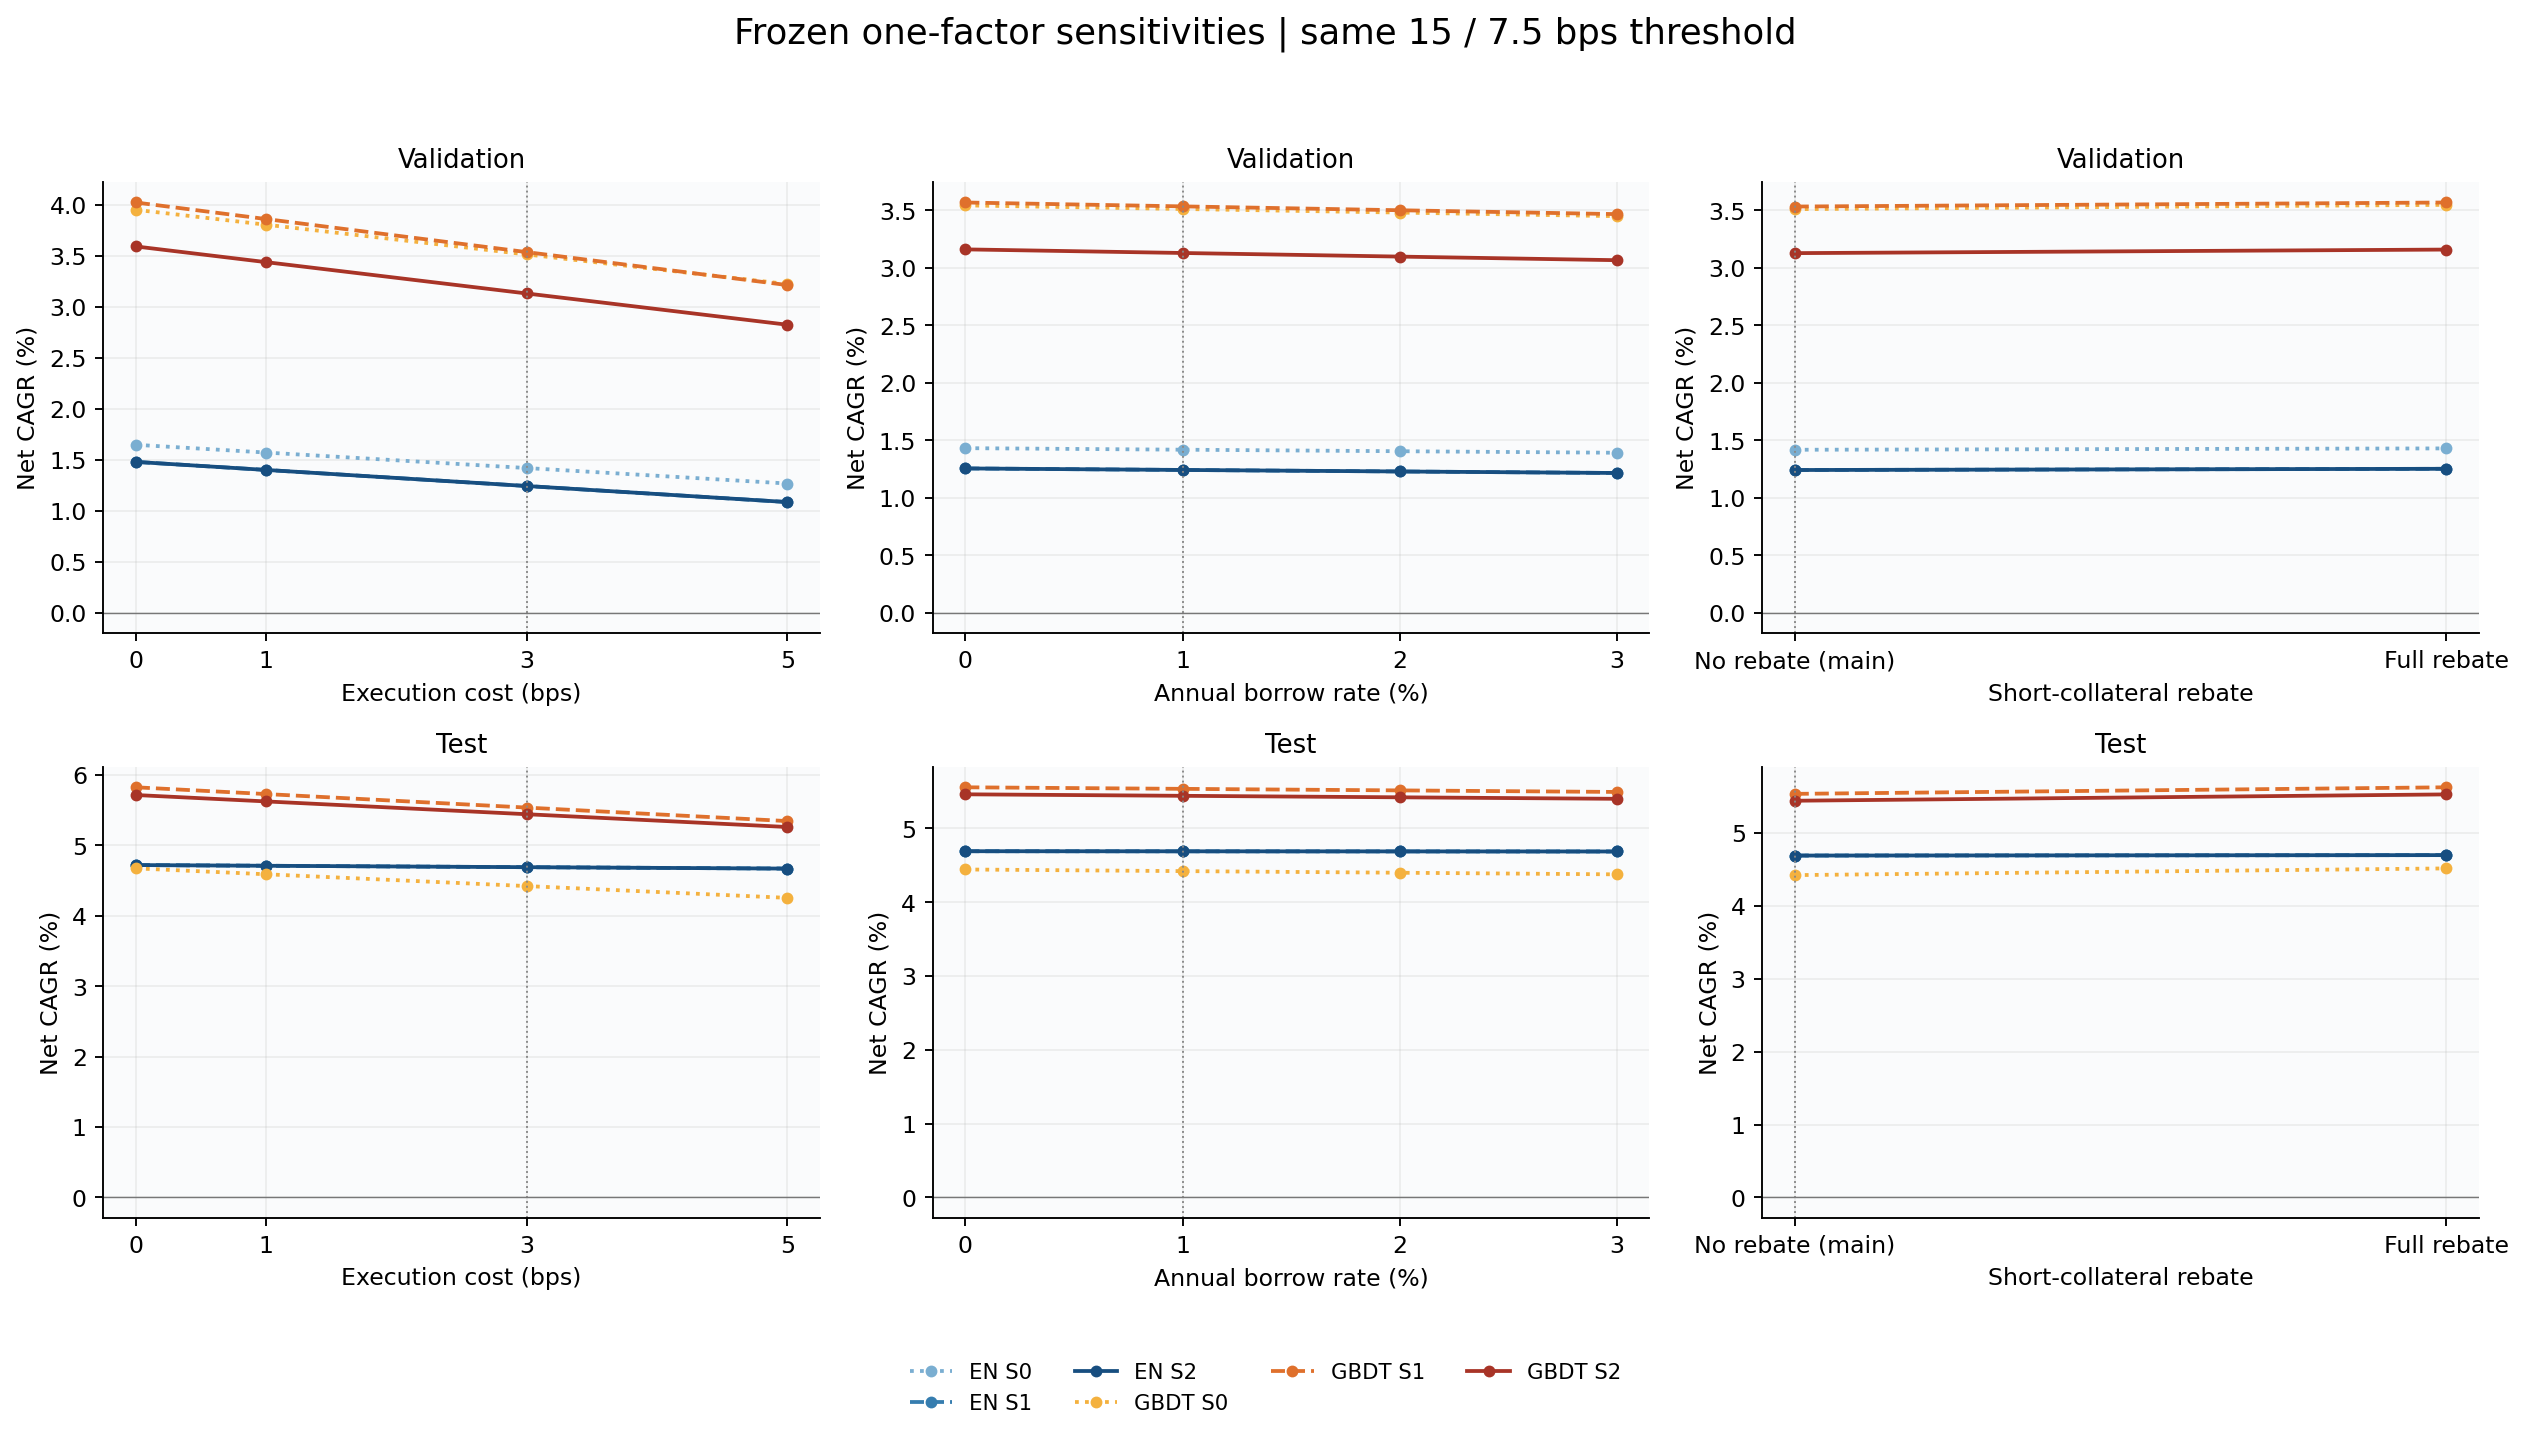

In [16]:
reporting = run_reporting(ROOT)
REPORT_OUT = OUT / 'reporting'
main_report_metrics = pd.read_csv(REPORT_OUT / 'main_metrics.csv', low_memory=False, float_precision='round_trip')
display(main_report_metrics[['split', 'series_id', 'annualized_net_return', 'annualized_net_volatility',
    'annualized_cash_excess_sharpe', 'max_drawdown', 'annualized_two_sided_turnover', 'holding_interval_fraction']])
display(pd.read_csv(REPORT_OUT / 'cost_robustness.csv'))
print('Reused main paths:', reporting['main_paths_reused'])
print('Sensitivity rows / new paths:', reporting['sensitivity_strategy_paths'], '/', reporting['new_alternative_strategy_paths'])
print('Original main strategies replayed:', reporting['main_strategy_replay'])
print('Chinese report:', REPORT_OUT / 'report_中文.md')
from IPython.display import Image as DisplayImage
display(DisplayImage(filename=str(REPORT_OUT / 'figures/01_nav_and_cash_relative.png'), width=1100))
display(DisplayImage(filename=str(REPORT_OUT / 'figures/04_cost_return_sensitivity.png'), width=1100))


## 17. Audit and next step

The manifests record input/output hashes, actual Python/pandas versions and checks.
Step 3 verifies missing signals and independence from future outcomes. Step 4 checks
mature training samples, delivered means, shared scoring keys and reproduction of
existing model metrics. Official models remain unchanged; steps 1-9 do not select a trading threshold.

Step 5 checks strict boundaries, fixed tie order, persistent holdings, capacity,
reversals, missing-signal guards, phase reset and ignored future-outcome fields.

Step 6 verifies percentage targets, SPY cancellation, daily share rebalancing,
net reversals, first/last trades, fractional shares and required execution quotes.

Step 7 checks signed dividend entitlement, collateral interest, borrow day counts,
self-financing NAV identities, first/final fees, return reconstruction and phase reset.

Step 8 verifies one-factor cost settings, unchanged thresholds/pair rules, exact
main-case reproduction, net fee allocation and nonzero financing sensitivity.

Step 9 checks monthly mature labels, training-only scaling, 2012-only calibration,
frozen diagnostic parameters, exact forecast coverage, complete-sector ranking and source hashes.

Step 10 verifies all validation opens, independent initial cash and final liquidation,
initial/final costs, all cash intervals, common return keys, net asset fees and the
pre-registered equal-weight objective/tie rule. Test portfolios are not replayed.

Step 11 verifies the frozen protocol, original signal-time inputs, both phase
endpoints, independent cash/share resets, final liquidation, return intervals,
initial/final fees, available RF intervals, net trades and unchanged historical
inputs. Identical EN test forecasts must give identical deterministic ledgers.
These phase acceptance checks do not complete the broader step-13 audit.

Step 12 checks fee-funded fixed SPY shares, old-share dividend timing, dividend-cash
interest, exact adjacent RF intervals, both end fees, phase resets, cash compounding
and agreement with the saved strategy cash references. These acceptance checks do
not complete the broader step-13 audit or full step-14 report and sensitivities.

Step 13 independently reconciles source quotes, prior/current signed shares,
cash and NAV, dividends, RF interest, short collateral/borrow, fees and every
saved return/summary. It rebuilds as-of eligibility, checks an independent pair
reference, reversed input order, selected single-open calculations and identical
forecast paths. The complete audit cache is hash-verified without repeat work.

Step 14 checks the frozen sample-volatility, initial-fee drawdown and interval
statistics, main-case reproduction, all six strategies in each of eight cost
settings, independent phase starts/final liquidation, unchanged pair targets,
actual net execution fees, cash/borrow calculations and complete checkpoint hashes.
Figures and the Chinese report are generated from the saved reporting tables.


In [17]:
checks = pd.DataFrame(alignment['checks'])
assert checks['passed'].all()
print('All', len(checks), 'panel/time checks passed.')
display(checks.loc[~checks['check'].str.startswith('prior_date_')].reset_index(drop=True))
policy_checks = pd.DataFrame(eligibility['checks'])
assert policy_checks['passed'].all()
print('All', len(policy_checks), 'signal-policy checks passed.')
display(policy_checks)
baseline_checks = pd.DataFrame(baselines['checks'])
assert baseline_checks['passed'].all()
print('All', len(baseline_checks), 'baseline checks passed.')
display(baseline_checks)
pair_checks = pd.DataFrame(pair_rules['checks'])
assert pair_checks['passed'].all()
print('All', len(pair_checks), 'pair-decision checks passed.')
display(pair_checks)
execution_checks = pd.DataFrame(execution['checks'])
assert execution_checks['passed'].all()
print('All', len(execution_checks), 'weight/net-trade checks passed.')
display(execution_checks)
ledger_checks = pd.DataFrame(ledger['checks'])
assert ledger_checks['passed'].all()
print('All', len(ledger_checks), 'ledger checks passed.')
display(ledger_checks)
cost_checks = pd.DataFrame(costs['checks'])
assert cost_checks['passed'].all()
print('All', len(cost_checks), 'cost-policy checks passed.')
display(cost_checks)
oof_checks = pd.DataFrame(oof['checks'])
assert oof_checks['passed'].all()
print('All', len(oof_checks), 'training OOF checks passed.')
display(oof_checks)
threshold_checks = pd.DataFrame(thresholds['checks'])
assert threshold_checks['passed'].all()
print('All', len(threshold_checks), 'threshold-selection checks passed.')
display(threshold_checks)
phase_checks = pd.DataFrame(phases['checks'])
assert phase_checks['passed'].all()
print('All', len(phase_checks), 'phase-evaluation checks passed.')
display(phase_checks)
investment_checks = pd.DataFrame(investment_benchmarks['checks'])
assert investment_checks['passed'].all()
print('All', len(investment_checks), 'investment-benchmark checks passed.')
display(investment_checks)
consistency_checks = pd.DataFrame(consistency['checks'])
assert consistency_checks['passed'].all()
print('All', len(consistency_checks), 'independent consistency-audit checks passed.')
display(consistency_checks)
reporting_checks = pd.DataFrame(reporting['checks'])
assert reporting_checks['passed'].all()
print('All', len(reporting_checks), 'reporting and sensitivity checks passed.')
display(reporting_checks)
print('Pending (current step-14 status):')
for item in reporting['not_yet_checked']:
    print('-', item)


All 134 panel/time checks passed.


,check,passed,detail
0,current_intake_hashes,True,The combined forecasts and both sources match ...
1,shared_panel_schema,True,The shared panel retains the schema declared b...
2,unique_panel_keys,True,One row per date/ticker
3,panel_boolean_flags,True,"Flags are booleans, not nonempty strings"
4,panel_sector_ids,True,The same nine sectors
5,shared_spy_calendar,True,"Panel dates match the 5,218-date aligned SPY c..."
6,rectangular_panel,True,All nine sectors are retained on every calenda...
7,data_cutoff,True,Calendar ends at the declared data cutoff
8,calendar_mapping_split,True,Matches next/second-next SPY date and New York...
9,calendar_mapping_entry_date,True,Matches next/second-next SPY date and New York...


All 14 signal-policy checks passed.


,check,passed,detail
0,future_fields_can_be_removed,True,"Trading policy runs with no target, label, exi..."
1,future_values_do_not_change_actions,True,All non-whitelisted panel fields changed; sign...
2,one_missing_prediction,True,Affected strategy requests next-open flat targ...
3,other_strategies_unaffected,True,A single missing model forecast does not close...
4,whole_strategy_day_missing,True,Affected strategy requests next-open flat targ...
5,nonfinite_prediction_nan,True,Affected strategy requests next-open flat targ...
6,nonfinite_prediction_positive_infinity,True,Affected strategy requests next-open flat targ...
7,nonfinite_prediction_negative_infinity,True,Affected strategy requests next-open flat targ...
8,fit_after_signal,True,Affected strategy requests next-open flat targ...
9,invalid_feature_flag,True,Affected strategy requests next-open flat targ...


All 24 baseline checks passed.


,check,passed,detail
0,full_export_keys_elastic_net,True,Full export and seven-column handoff contain e...
1,full_export_values_elastic_net,True,Full export corresponds to the same prediction...
2,one_mean_per_month_sector_elastic_net,True,The delivered mean is constant across days/sch...
3,full_export_keys_gbdt,True,Full export and seven-column handoff contain e...
4,full_export_values_gbdt,True,Full export corresponds to the same prediction...
5,one_mean_per_month_sector_gbdt,True,The delivered mean is constant across days/sch...
6,canonical_keys_unique,True,One common baseline per date/sector
7,one_cutoff_per_month,True,All baseline sectors share the model schedule
8,upstream_training_keys,True,All 945 month/sector training records match th...
9,upstream_training_sample_counts,True,Training and mature cross-partition sample cou...


... (17 outputs left out)

,category,phase,identity,check,passed,rows,max_abs_error,atol,rtol,detail
0,signal_inputs,both,all,future_fields_and_row_order_do_not_change_signals,True,118692,NaN,NaN,NaN,Exact value equality
1,signal_inputs,both,all,future_fields_and_row_order_do_not_change_dail...,True,13188,NaN,NaN,NaN,Exact value equality
2,signal_inputs,both,all,rebuilt_sector_readiness_matches_registered_si...,True,118692,NaN,NaN,NaN,Exact value equality
3,signal_inputs,both,all,rebuilt_phase_guards_match_registered_actions,True,13188,NaN,NaN,NaN,Exact value equality
4,signal_inputs,both,all,signal_at_utc_matches,True,13188,NaN,NaN,NaN,
...,...,...,...,...,...,...,...,...,...,...
1044,comparison,both,cash,net_cumulative_return_join,True,12,0.0,1.000000e-12,1.000000e-12,
1045,comparison,both,cash,annualized_net_return_join,True,12,0.0,1.000000e-12,1.000000e-12,
1046,comparison,both,cash,terminal_wealth_ratio,True,12,0.0,1.000000e-12,1.000000e-12,
1047,comparison,both,cash,all_strategy_cash_references_agree,True,12,0.0,1.000000e-12,1.000000e-12,


All 215 reporting and sensitivity checks passed.


,phase,scenario_id,check,passed,detail
0,fixture,metric,initial_fee_drawdown_precedes_first_return,True,Using only real-interval cumulative returns wo...
1,fixture,metric,no_initial_zero_length_return,True,
2,fixture,metric,sample_net_volatility,True,
3,fixture,metric,holding_uses_interval_start,True,
4,fixture,metric,two_sided_turnover_keeps_both_ends,True,
...,...,...,...,...,...
210,both,figure,05_cost_sharpe_sensitivity_png_valid,True,"PNG decoded, dimensions checked"
211,both,figure,05_cost_sharpe_sensitivity_svg_valid,True,SVG parsed
212,both,figure,06_calendar_year_returns_png_valid,True,"PNG decoded, dimensions checked"
213,both,figure,06_calendar_year_returns_svg_valid,True,SVG parsed


Pending (current step-14 status):
- step 15: final package and handoff
- step 16: optional extensions only if separately requested


## 18. Step 15 - Final inventory and handoff

Steps 1-15 are complete. Start with [the final handoff](../最终回测交接说明_yae.md)
and [the Chinese results report](../results/backtest/reporting/report_中文.md).
The file inventory, observed environment and handoff checks are saved under
`results/backtest/handoff/`. A review archive and complete snapshot preserve
the original relative directory layout and the sibling authoritative protocol.

From the repository root, run `python -B scripts/backtest_handoff.py --verify-only`
for standard-library, read-only hash verification. The review archive is for
reading; use the full snapshot for Notebook 05. The 17 existing code cells and
all saved outputs are unchanged in step 15; only notebook documentation was
updated. The recorded sequential Python verification remains valid for those
code cells; native Jupyter kernel execution is not claimed.

Earlier manifests retain historical pending flags. Current step-15 status is
owned by `results/backtest/handoff/run_manifest.json`; detached archive hashes
are beside the ZIP files. Step 16 optional extensions are not executed.
